# Modeling Sim2real Gap from Backlash in Blind Reorientation

Given a joint with joint-angle $q$. Backlash is the error that occurs from gaps between gear teeth in a transmission. When a joint reverses direction, backlash requires that a joint travel a certain angular distance before the transmission begins to spin the encoder again. We visualize this in the next two cells by moving a single joint on the ShadowHand in Isaac Lab. In the markdown after we describe how we model backlash. 

There are four videos, one that visualizes the shadow hand according to joint angles $q$ (the truth), one that visualizes with $q_\text{meas}$ (what the policy percieves), a third that overlays the two to provide us with a sense of how large the error is, and a fourth that does the same but zooms in. 

In [1]:
# The backlash model on ONE joint: the index-finger proximal flexion joint (robot0_FFJ2, 0..90 deg) is driven through a path with reversals while every
# other joint stays still. The true angle is what the hand really does; the "perceived" angle is what a policy would be told by an encoder behind a
# gearbox with backlash at gear ratio N = 200 (api/blind_repose.py MeasurementModel, backlash only: a play operator with half-width
# h = (N / 15) * 0.1 deg = 1.33 deg). The perceived hand is the hand posed at the perceived joint angles (the sim's kinematics, api/hand_viz.py).
# The readings are the output of the real MeasurementModel on this path (scripts/diagnostics/dump_joint_demo.py, run on the node; its check against
# the numpy copy in utils/hand_render.py is exact) and live in DATA below. Rendering is numpy + PIL only (CPU, parallel over frames; about a minute).
# Panels, left to right: true hand | perceived hand | overlay | overlay zoomed on the true fingertip (the camera follows it). Orange = perceived; the
# white circle is the true fingertip (distal link origin) and the orange dot the perceived one.
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils" / "hand_render.py").exists())
sys.path.insert(0, str(ROOT))
from api import video
from utils import hand_render as hr

DATA = ROOT / ".cache/tmp/joint_demo"
meshes = hr.load_meshes(DATA / "meshes.npz")
R = hr.load_rollout(DATA / "joint_demo.npz")
J, N = int(R["joint_index"]), float(R["n"])
names = meshes["joint_names"]
qt, qm = np.degrees(R["q_true"][:, 0, J]), np.degrees(R["q_meas"][:, 0, J])
T = len(qt)
tt = np.arange(T) / 30  # 30 Hz control
print(f"joint {names[J]}: N = {N:g}, backlash half-width h = {math.degrees(hr.half_width(N)):.2f} deg; {T} frames ({T / 30:.1f} s), "
      f"max |perceived - true| = {np.abs(qm - qt).max():.3f} deg")

view = hr.finger_view(meshes, R, flip=True)
fb = {b: i for i, b in enumerate(meshes["body_names"])}["robot0_ffdistal"]


def caption(t):
    err = 1e3 * np.linalg.norm(R["fk_meas_pos"][t, 0, fb] - R["fk_true_pos"][t, 0, fb])
    return f"t = {t / 30:.1f} s   true {qt[t]:.1f} deg   perceived {qm[t]:.1f} deg   error {qm[t] - qt[t]:+.2f} deg   fingertip error {err:.1f} mm"


def pad16(f):
    """Pad frames to multiples of 16 px for the video encoder."""
    h, w = f.shape[1:3]
    return np.pad(f, ((0, 0), (0, -h % 16), (0, -w % 16), (0, 0)), constant_values=18)


STRIDE, WORKERS = 2, 12  # every STRIDE-th control step, played at 30 / STRIDE fps (real time)
TS = list(range(0, T, STRIDE))
t0 = time.time()
frames = hr.render_frames(meshes, R, TS, 0, title_fn=caption, size=300, workers=WORKERS, joint_kw=dict(view=view, dist=0.26, zoom_dist=0.10))
print(f"{len(TS)} frames of {frames.shape[2]}x{frames.shape[1]} in {time.time() - t0:.0f}s")
display(video.show(list(pad16(frames)), fps=30 / STRIDE, width=1200))


joint robot0_FFJ2: N = 200, backlash half-width h = 1.33 deg; 241 frames (8.0 s), max |perceived - true| = 1.333 deg


121 frames of 1200x330 in 61s


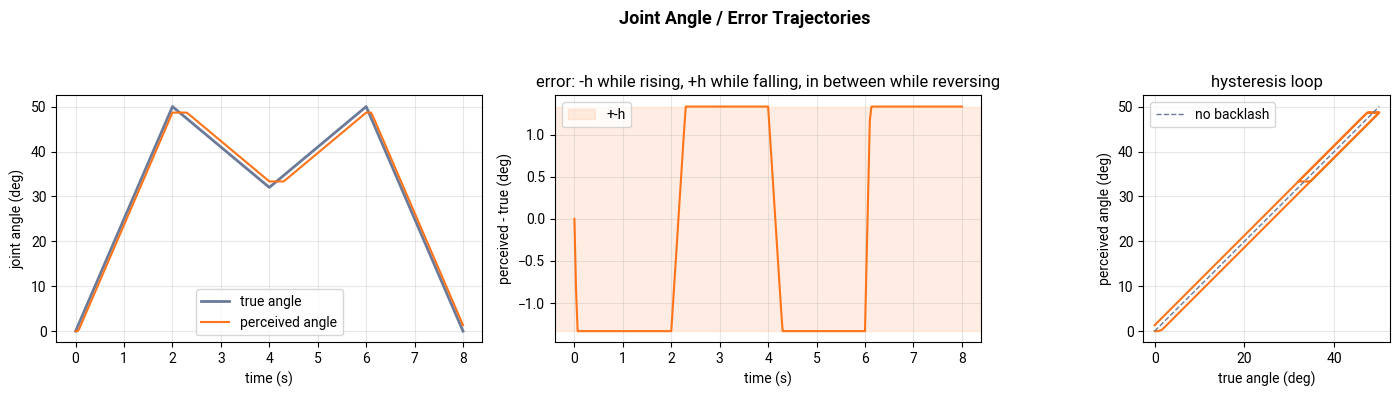

In [2]:
# The readings of the video above (uses qt, qm, tt, N, names, J from the previous cell). The perceived angle trails the true one by h in the direction
# of motion, freezes while the joint reverses (it must cross the whole 2h dead band before the encoder sees anything), then trails on the other
# side: at the SAME true angle the reading differs by 2h depending on the direction the joint arrived from. Right: perceived vs true angle is a
# hysteresis loop of width 2h.
from utils.fonts import use_roboto

use_roboto()
plt.rcParams.update({"font.family": "Roboto", "pdf.fonttype": 42, "ps.fonttype": 42})
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
h = math.degrees(hr.half_width(N))
ax[0].plot(tt, qt, color="#6b7a99", lw=2, label="true angle")
ax[0].plot(tt, qm, color="#ff7319", lw=1.5, label="perceived angle")
ax[0].set(xlabel="time (s)", ylabel="joint angle (deg)")
ax[1].axhspan(-h, h, color="#ff7319", alpha=0.12, label="+-h")
ax[1].plot(tt, qm - qt, color="#ff7319")
ax[1].set(xlabel="time (s)", ylabel="perceived - true (deg)", title="error: -h while rising, +h while falling, in between while reversing")
ax[2].plot(qt, qm, color="#ff7319", lw=1.5)
ax[2].plot([0, 50], [0, 50], color="#6b7a99", ls="--", lw=1, label="no backlash")
ax[2].set(xlabel="true angle (deg)", ylabel="perceived angle (deg)", title="hysteresis loop", aspect="equal")
for a in ax:
    a.grid(alpha=0.3)
    a.legend(loc="best")
fig.suptitle("Joint Angle / Error Trajectories", fontweight="bold", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


### Modeling Backlash

The model for backlash that was used to generate these trajectories is quite simple. Let $q$ be the true joint angle and $q_\text{meas}$ be the measured joint-angle from the encoder. Let $2h$ be the angular gap caused by gear tooth travel. Then, at every timestep we update 

$$q_\text{meas} \leftarrow \operatorname{clip}(q_\text{meas}, q-h, q+h)$$

This requires that $q_\text{meas}$ remain within $h$ of $q$, but otherwise allows $q$ to move freely without impacting $q_\text{meas}$. 

### Creating a test-bed for Backlash

In a seperate notebook, we train a blind PPO policy for the cube reorientation task in Isaac Lab. The policy takes in a 48-dim joint pos/vel vector, 65-dim finger pos/rot/vel vector, the last produced 20-dim action vector, and a 4-dim rotation command indicating.

The 4-dim rotation command indicates the rotation axis and angular distance to the cube reorientation target, but *crucially* does *not* provide any information about the current orientation / position of the cube. Thus the state of the cube must be inferred from proprioception, touch or force sensing. 

In the following cell we display our frozen policy:

In [3]:
# The frozen blind-proprio policy in a clean rollout (no backlash: it reads the true joint angles): the true hand, the cube and the goal orientation
# (green wireframe, drawn at the cube's position so the rotation still to go is visible; it jumps when a goal is reached; the box counts the goals
# reached so far). This is the first panel of the clean run's video in repose-backlash-visual.ipynb, i.e. WITHOUT the hand the backlash model
# perceives; its first frame is the first frame of that video. Same data (scripts/diagnostics/dump_hand_viz.py, run on the node), env and camera;
# every VIZ_STRIDE-th control step (30 Hz) played at 30 / VIZ_STRIDE fps, i.e. real time. CPU only, about a minute and a half.
# (Uses ROOT, hr, video, pad16 and the imports of the first cell.)
VIZ = ROOT / ".cache/tmp/hand_viz_b"
VIZ_ENV, VIZ_CAM_T, VIZ_SIZE, VIZ_STRIDE, VIZ_WORKERS = 0, 100, 420, 2, 12  # env shown; the frame the camera is aimed at; panel size in px
viz_meshes = hr.load_meshes(VIZ / "meshes.npz")
viz_clean = hr.load_rollout(VIZ / "rollout_N0.npz")
viz_cam = hr.default_camera(viz_meshes, viz_clean, VIZ_ENV, VIZ_CAM_T)
viz_ts = list(range(0, viz_clean["q_true"].shape[0], VIZ_STRIDE))


def viz_caption(t):
    ang = math.degrees(hr.rot_angle(viz_clean["obj_quat"][t, VIZ_ENV], viz_clean["goal_quat"][t, VIZ_ENV]))
    return f"t = {t / 30:.1f} s   goal error {ang:.0f} deg"


t0 = time.time()
viz_frames = hr.render_frames(viz_meshes, viz_clean, viz_ts, VIZ_ENV, key="meas", title_fn=viz_caption, cam=viz_cam, size=VIZ_SIZE,
                              workers=VIZ_WORKERS, counter_fn=lambda t: viz_clean["succ"][t, VIZ_ENV])
viz_frames = viz_frames[:, :, :VIZ_SIZE]  # the frames are [true | perceived | overlay]; keep the true hand + cube
print(f"{len(viz_ts)} frames of {viz_frames.shape[2]}x{viz_frames.shape[1]} in {time.time() - t0:.0f}s")
display(video.show(list(pad16(viz_frames)), fps=30 / VIZ_STRIDE, width=VIZ_SIZE))


100 frames of 420x450 in 56s


### Performance Degradation as Backlash Width $2h$ Increases



Using our model for backlash, we can pass $q_\text{meas}$ into our policy instead of $q$. Rolling out the initial policy we find a natural degradation in performance as the width $h$ increases. In the following cell we plot performance drop off as the % dropoff from the no backlash median for each $h$, and we plot the cube drop frequency for each $h$ as wel.  

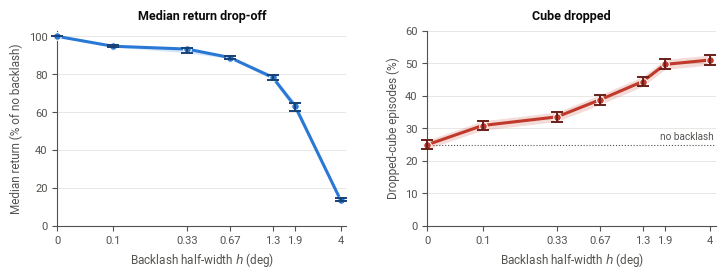

In [4]:
# Camera-ready figure: degradation of the frozen blind-proprio policy as the backlash half-width h grows (N = 0 ... 600).
# Reads the cached full-episode evals of repose-blind-meas-sweep.ipynb (no simulator, no GPU): the CLEAN-trained blind proprio policy with backlash
# only on the actor's joint encoders, greedy, 2048 envs x 2 counted episodes = 4096 episodes per point; N = 0 is the no-backlash baseline.
# Gear ratio N maps to the half-width by our assumed h = 0.1 deg * N / 15 (plotted: N = 0, 15, 50, 100, 200, 288, 600). Error bars and bands are 95% percentile
# bootstraps over episodes (2 per env in one batched run, so they understate the uncertainty; one checkpoint, one eval seed). Absolute levels are
# specific to 2048 envs (see ai-notes).
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb

from utils.experiment_cache import ExperimentCache
from utils.fonts import use_roboto

TASK = "Isaac-Repose-Cube-Shadow-Blind-Proprio-v0"
CKPT = "logs/rl_games/blind_repose/blind-proprio/nn/last_blind_repose_ep_5000_rew_3925.8337.pth"
NS = [0, 15, 50, 100, 200, 288, 600]
TICK_NS = NS  # the N whose h = H0_DEG * N / N_REF is labelled on the x axis
N_REF, H0_DEG, MAX_LEN, N_BOOT = 15.0, 0.1, 600, 2000


cache = ExperimentCache()
episodes = {}  # N -> (return, length) of the counted episodes
for meta in cache.dir.glob("*.json"):
    m = json.loads(meta.read_text())
    p = m.get("params") or {}
    if m.get("experiment") != "repose_blind_meas_sweep" or p.get("task") != TASK or p.get("ckpt") != CKPT or p.get("num_envs") != 2048:
        continue
    cfg = p["cfg"]
    if cfg == dict(n=0) or (cfg.get("backlash") and not cfg.get("stiction") and not cfg.get("chaos")):
        ev = cache.get(meta.stem)
        episodes[int(cfg["n"])] = (ev["return"], ev["length"])
missing = [N for N in NS if N not in episodes]
assert not missing, f"not evaluated (run repose-blind-meas-sweep.ipynb with SCHEMES=clean,backlash): N = {missing}"

rng = np.random.default_rng(0)
boot_median = lambda r: np.median(r[rng.integers(0, len(r), (N_BOOT, len(r)))], axis=1)


def wilson(k, n, z=1.96):
    """95% Wilson interval of a proportion, in %."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - half), 100 * (centre + half)


h = np.array([N / N_REF * H0_DEG for N in NS])
base_med, base_boot = np.median(episodes[0][0]), boot_median(episodes[0][0])
ret, ret_lo, ret_hi, cube, cube_lo, cube_hi = [], [], [], [], [], []
for N in NS:
    r, l = episodes[N]
    ret.append(100 * np.median(r) / base_med)
    lo, hi = (100.0, 100.0) if N == 0 else np.percentile(100 * boot_median(r) / base_boot, [2.5, 97.5])  # N = 0 is the reference itself
    ret_lo.append(lo), ret_hi.append(hi)
    k = int((l < MAX_LEN - 1).sum())  # an episode shorter than the time limit ended because the cube was dropped
    cube.append(100 * k / len(l))
    lo, hi = wilson(k, len(l))
    cube_lo.append(lo), cube_hi.append(hi)

use_roboto()
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, RED = "#2a78d6", "#c0392b"
plt.rcParams.update({
    "font.family": "Roboto", "font.size": 8, "axes.labelsize": 8.5, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "figure.facecolor": "white", "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": MUTED, "axes.linewidth": 0.8,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

FIG_W, AXES_H = 7.2, 2.2
fig_h = AXES_H + 0.75
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, fig_h))
panels = [
    (axes[0], ret, ret_lo, ret_hi, BLUE, "Median return drop-off", "Median return (% of no backlash)", (0, 103), np.arange(0, 101, 20)),
    (axes[1], cube, cube_lo, cube_hi, RED, "Cube dropped", "Dropped-cube episodes (%)", (0, 60), np.arange(0, 61, 10)),
]
for ax, y, lo, hi, color, title, ylabel, ylim, yticks in panels:
    ax.set_xscale("symlog", linthresh=H0_DEG, linscale=0.35)
    ax.fill_between(h, lo, hi, color=color, alpha=0.18, lw=0)
    ax.plot(h, y, color=color, lw=2.2, marker="o", ms=5.5, mec="white", mew=0.8, clip_on=False, zorder=10)
    ax.errorbar(h, y, yerr=[np.asarray(y) - lo, np.asarray(hi) - y], fmt="none", ecolor=[0.55 * c for c in to_rgb(color)], elinewidth=1.4, capsize=4,
                capthick=1.4, clip_on=False, zorder=11)  # 95% CI, drawn over the markers (on the left it is smaller than a marker)
    ax.set(xlim=(0, h[-1] * 1.1), ylim=ylim, yticks=yticks)
    ax.set_xticks([N / N_REF * H0_DEG for N in TICK_NS])
    ax.set_xticklabels([f"{N / N_REF * H0_DEG:.2g}" for N in TICK_NS])
    ax.minorticks_off()
    ax.set_xlabel(r"Backlash half-width $h$ (deg)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="center", fontweight="bold", pad=8)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].axhline(cube[0], color=MUTED, lw=0.8, ls=":", zorder=1)
axes[1].annotate("no backlash", (h[-1] * 1.1, cube[0]), xytext=(-2, 4), textcoords="offset points", ha="right", color=MUTED, fontsize=7.2)
fig.subplots_adjust(left=0.075, right=0.99, top=1 - 0.38 / fig_h, bottom=0.62 / fig_h, wspace=0.28)
plt.show()


### Visualizing the Performance Dropoff

In the next cell we will visualizie three runs with $h\in\{0, 0.67, 1.9\}$. We usea similar overlay as the first video demonstrating backlash on a single joint to provide intuition for the discrepency between reality and what the policy can see. 

In [5]:
# Rollout videos of three runs of the frozen blind-proprio policy (same seed, greedy) with backlash on the actor's joint readings: h = 0 (clean),
# 0.67 and 1.9 deg, i.e. N = 0, 100 and 288 (h = (N / 15) * 0.1 deg on every joint; api/blind_repose.py MeasurementModel, backlash only). One video per run,
# same camera. Left to right: the TRUE hand + cube | the hand the policy PERCEIVES from its backlash-corrupted joint readings (it does not see the cube)
# | overlay (orange = perceived; white circle = true fingertip, orange dot = perceived fingertip). The green wireframe cube is the GOAL orientation (drawn
# at the cube's position so the rotation still to go is visible; it jumps when a goal is reached); the box top-left counts the goals reached so far; the
# caption gives the time, the cube's orientation error to the goal and the mean fingertip error. Data: scripts/diagnostics/dump_hand_viz.py
# (NS=0,100,288, run on the node). Frames are every VSTRIDE-th control step (30 Hz) played at 30 / VSTRIDE fps, i.e. real time. CPU only, about a minute per run.
# (Uses ROOT, hr, video, pad16 and the imports of the first cell.)
VIDS = ROOT / ".cache/tmp/hand_viz_c"
VID_NS, VID_ENV, VID_CAM_T = [0, 100, 288], 0, 100  # gear ratios; env shown; the frame the camera is aimed at (as above)
vmeshes = hr.load_meshes(VIDS / "meshes.npz")
vruns = {n: hr.load_rollout(VIDS / f"rollout_N{n}.npz") for n in VID_NS}
vtips = vmeshes["finger_bodies"]
vcam = hr.default_camera(vmeshes, vruns[0], VID_ENV, VID_CAM_T)  # fixed camera for all frames and runs


def vlabel(n):
    return "clean (h = 0)" if n == 0 else f"N = {n} (h = {math.degrees(hr.half_width(n)):.2f} deg)"


def vcaption(n, r):
    def f(t):
        err = 1e3 * np.linalg.norm(r["fk_meas_pos"][t, VID_ENV][vtips] - r["fk_true_pos"][t, VID_ENV][vtips], axis=-1).mean()
        ang = math.degrees(hr.rot_angle(r["obj_quat"][t, VID_ENV], r["goal_quat"][t, VID_ENV]))
        return f"{vlabel(n)}   t = {t / 30:.1f} s   goal error {ang:.0f} deg   fingertip error {err:.1f} mm"

    return f


VSTRIDE, VWORKERS = 2, 12
vts = list(range(0, vruns[0]["q_true"].shape[0], VSTRIDE))
vframes = {}
for n in VID_NS:
    t0 = time.time()
    vframes[n] = hr.render_frames(vmeshes, vruns[n], vts, VID_ENV, key="meas", title_fn=vcaption(n, vruns[n]), cam=vcam, workers=VWORKERS,
                                  counter_fn=lambda t, r=vruns[n]: r["succ"][t, VID_ENV])
    print(f"N={n}: {len(vts)} frames of {vframes[n].shape[2]}x{vframes[n].shape[1]} in {time.time() - t0:.0f}s")

for n in VID_NS:
    print(vlabel(n))
    display(video.show(list(pad16(vframes[n])), fps=30 / VSTRIDE, width=960))


N=0: 100 frames of 960x350 in 54s


N=100: 100 frames of 960x350 in 52s


N=288: 100 frames of 960x350 in 52s
clean (h = 0)


N = 100 (h = 0.67 deg)


N = 288 (h = 1.92 deg)
